# 01 — Sample and Profile the H&M Data

**Goal of this notebook (Week 1):**
1. Take a random **10% sample of customers** and keep **all** of their transactions.
2. Profile all three tables: size, types, nulls, value ranges, categories.
3. Run data-quality checks that decide how we clean the data in Week 2.
4. Save compact Parquet files for the rest of the project.

**Why sample by customer, not by row?** Retention and customer value depend on each customer's *full* history. Sampling random rows would keep fragments of everyone's history and make repeat-purchase rates look artificially low.

> Run this from the `notebooks/` folder with the three CSVs in `data/raw/`. The sampling step reads 31M rows in chunks and takes a few minutes; after the first run it is skipped automatically.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.4f}".format)

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

SAMPLE_FRAC = 0.10
SEED = 42  # fixed so the sample is reproducible

for f in ["transactions_train.csv", "customers.csv", "articles.csv"]:
    print(f"{f:28s}", "OK" if (RAW / f).exists() else "MISSING")

transactions_train.csv       OK
customers.csv                OK
articles.csv                 OK


## 1. Sample 10% of customers

In [2]:
customers_all = pd.read_csv(RAW / "customers.csv")
print(f"All customers: {len(customers_all):,}")

customers = customers_all.sample(frac=SAMPLE_FRAC, random_state=SEED).reset_index(drop=True)
sample_ids = set(customers["customer_id"])
print(f"Sampled customers: {len(customers):,}")
del customers_all

All customers: 1,371,980


Sampled customers: 137,198


## 2. Filter transactions in chunks

The full transactions file is too big to load at once on most laptops, so we read it 2M rows at a time and keep only rows belonging to sampled customers. `article_id` is read as an integer in both tables so the join works (in the CSV it has a leading zero, e.g. `0108775015`).

In [3]:
TX_SAMPLE = PROCESSED / "transactions_sample.parquet"

if TX_SAMPLE.exists():
    tx = pd.read_parquet(TX_SAMPLE)
    print("Loaded existing sample.")
else:
    kept, total = [], 0
    reader = pd.read_csv(
        RAW / "transactions_train.csv",
        chunksize=2_000_000,
        parse_dates=["t_dat"],
        dtype={"article_id": "int32", "price": "float32", "sales_channel_id": "int8"},
    )
    for i, chunk in enumerate(reader, 1):
        total += len(chunk)
        kept.append(chunk[chunk["customer_id"].isin(sample_ids)])
        print(f"chunk {i}: read {total:,} rows so far")
    tx = pd.concat(kept, ignore_index=True)
    tx.to_parquet(TX_SAMPLE, index=False)
    print(f"Kept {len(tx):,} of {total:,} rows ({len(tx)/total:.1%})")

print(f"Transactions in sample: {len(tx):,}")
print(f"Date range: {tx['t_dat'].min().date()} to {tx['t_dat'].max().date()}")

chunk 1: read 2,000,000 rows so far


chunk 2: read 4,000,000 rows so far


chunk 3: read 6,000,000 rows so far


chunk 4: read 8,000,000 rows so far


chunk 5: read 10,000,000 rows so far


...

chunk 13: read 26,000,000 rows so far


chunk 14: read 28,000,000 rows so far


chunk 15: read 30,000,000 rows so far


chunk 16: read 31,788,324 rows so far


Kept 3,162,621 of 31,788,324 rows (9.9%)
Transactions in sample: 3,162,621
Date range: 2018-09-20 to 2020-09-22


In [4]:
articles = pd.read_csv(RAW / "articles.csv", dtype={"article_id": "int32"})
print(f"Articles: {len(articles):,}")

Articles: 105,542


## 3. Profile each table

In [5]:
def profile(df, name):
    print(f"=== {name}: {len(df):,} rows x {df.shape[1]} columns ===")
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulls": df.isna().sum(),
        "null_%": (df.isna().mean() * 100).round(2),
        "unique": df.nunique(),
    })
    return out

profile(tx, "transactions")

=== transactions: 3,162,621 rows x 5 columns ===


,dtype,nulls,null_%,unique
t_dat,datetime64[us],0,0.0000,734
customer_id,str,0,0.0000,136306
article_id,int32,0,0.0000,85923
price,float32,0,0.0000,6323
sales_channel_id,int8,0,0.0000,2


In [6]:
profile(customers, "customers")

=== customers: 137,198 rows x 7 columns ===


,dtype,nulls,null_%,unique
customer_id,str,0,0.0000,137198
FN,float64,89727,65.4000,1
Active,float64,90991,66.3200,1
club_member_status,str,606,0.4400,3
fashion_news_frequency,str,1621,1.1800,3
age,float64,1613,1.1800,79
postal_code,str,0,0.0000,99154


In [7]:
profile(articles, "articles")

=== articles: 105,542 rows x 25 columns ===


,dtype,nulls,null_%,unique
article_id,int32,0,0.0000,105542
product_code,int64,0,0.0000,47224
prod_name,str,0,0.0000,45875
product_type_no,int64,0,0.0000,132
product_type_name,str,0,0.0000,131
product_group_name,str,0,0.0000,19
graphical_appearance_no,int64,0,0.0000,30
graphical_appearance_name,str,0,0.0000,30
colour_group_code,int64,0,0.0000,50
colour_group_name,str,0,0.0000,50


### 3a. Transactions

In [8]:
print(f"Unique customers who bought: {tx['customer_id'].nunique():,}")
print(f"Unique articles bought:      {tx['article_id'].nunique():,}")
print()
print("Price (scaled, not real currency):")
print(tx["price"].describe())
print()
print("Sales channel share:")
print(tx["sales_channel_id"].value_counts(normalize=True).sort_index())

Unique customers who bought: 136,306
Unique articles bought:      85,923

Price (scaled, not real currency):


count   3,162,621.0000
mean            0.0278
std             0.0191
min             0.0002
25%             0.0158
50%             0.0254
75%             0.0339
max             0.5068
Name: price, dtype: float64

Sales channel share:
sales_channel_id
1   0.2987
2   0.7013
Name: proportion, dtype: float64


In [9]:
monthly = tx.groupby(tx["t_dat"].dt.to_period("M")).agg(
    items=("article_id", "size"),
    sales_value=("price", "sum"),
    customers=("customer_id", "nunique"),
)
monthly["online_share"] = (
    tx.assign(online=tx["sales_channel_id"].eq(2))
      .groupby(tx["t_dat"].dt.to_period("M"))["online"].mean()
)
monthly

,items,sales_value,customers,online_share
t_dat,,,,
2018-09,59871,"1,781.7532",14151,0.6446
2018-10,137637,"4,100.1704",27510,0.6919
2018-11,125284,"3,857.6211",27292,0.7135
2018-12,113899,"3,238.5474",25464,0.6136
2019-01,125528,"3,321.9438",24208,0.7356
2019-02,113582,"3,111.6877",23999,0.6653
2019-03,128282,"3,719.7996",24369,0.7167
2019-04,147638,"4,275.6372",26104,0.6991
2019-05,156366,"4,357.0747",27276,0.6858


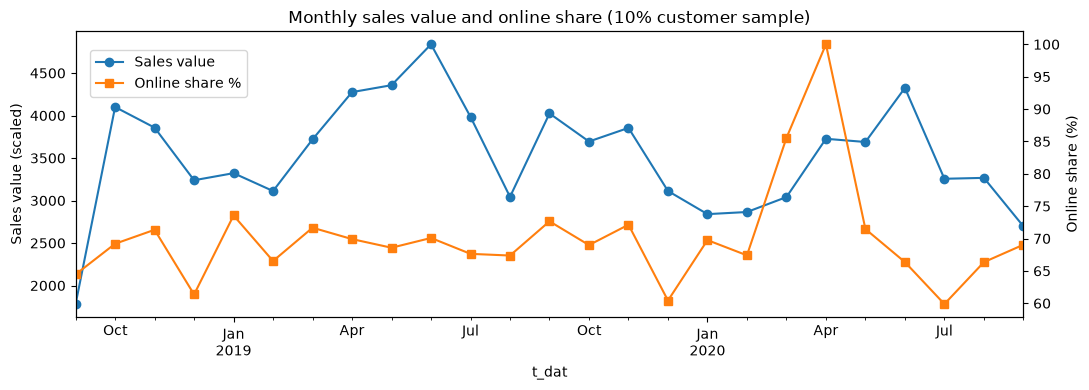

In [10]:
fig, ax1 = plt.subplots(figsize=(11, 4))
monthly["sales_value"].plot(ax=ax1, marker="o", label="Sales value")
ax1.set_ylabel("Sales value (scaled)")
ax2 = ax1.twinx()
(monthly["online_share"] * 100).plot(ax=ax2, color="tab:orange", marker="s", label="Online share %")
ax2.set_ylabel("Online share (%)")
ax1.set_title("Monthly sales value and online share (10% customer sample)")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
plt.tight_layout()
plt.savefig(FIGURES / "01_monthly_sales_online_share.png", dpi=150)
plt.show()

**Note:** the first and last months in the data may be partial. Check the min/max dates above before reading anything into them.

### 3b. Customers

In [11]:
for col in ["club_member_status", "fashion_news_frequency", "FN", "Active"]:
    print(f"--- {col} ---")
    print(customers[col].value_counts(dropna=False))
    print()

--- club_member_status ---
club_member_status
ACTIVE        127257
PRE-CREATE      9283
NaN              606
LEFT CLUB         52
Name: count, dtype: int64

--- fashion_news_frequency ---
fashion_news_frequency
NONE         87974
Regularly    47534
NaN           1621
Monthly         69
Name: count, dtype: int64

--- FN ---
FN
NaN       89727
1.0000    47471
Name: count, dtype: int64

--- Active ---
Active
NaN       90991
1.0000    46207
Name: count, dtype: int64



count   135,585.0000
mean         36.4278
std          14.3192
min          16.0000
25%          24.0000
50%          32.0000
75%          49.0000
max          99.0000
Name: age, dtype: float64


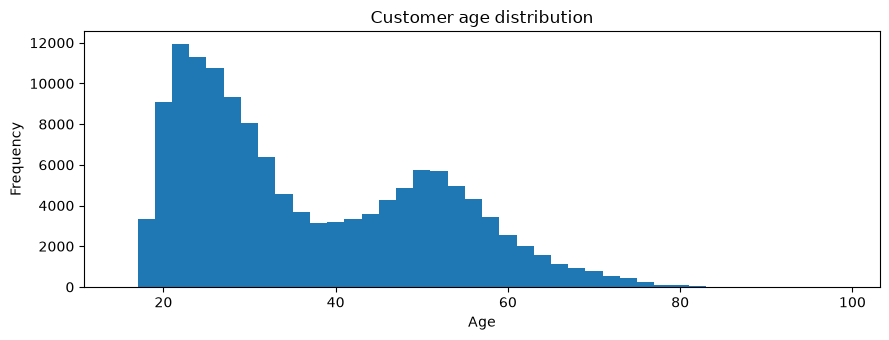

In [12]:
print(customers["age"].describe())
customers["age"].plot.hist(bins=range(15, 100, 2), figsize=(9, 3.5), title="Customer age distribution")
plt.xlabel("Age")
plt.tight_layout()
plt.savefig(FIGURES / "01_age_distribution.png", dpi=150)
plt.show()

### 3c. Articles

In [13]:
cat_cols = ["product_group_name", "product_type_name", "garment_group_name",
            "index_group_name", "index_name", "section_name", "department_name",
            "colour_group_name", "perceived_colour_master_name"]
articles[cat_cols].nunique().sort_values()

index_group_name                  5
index_name                       10
product_group_name               19
perceived_colour_master_name     20
garment_group_name               21
colour_group_name                50
section_name                     56
product_type_name               131
department_name                 250
dtype: int64

In [14]:
for col in ["product_group_name", "garment_group_name", "index_group_name"]:
    print(f"--- {col} ---")
    print(articles[col].value_counts().head(15))
    print()

--- product_group_name ---
product_group_name
Garment Upper body     42741
Garment Lower body     19812
Garment Full body      13292
Accessories            11158
Underwear               5490
Shoes                   5283
Swimwear                3127
Socks & Tights          2442
Nightwear               1899
Unknown                  121
Underwear/nightwear       54
Cosmetic                  49
Bags                      25
Items                     17
Furniture                 13
Name: count, dtype: int64

--- garment_group_name ---
garment_group_name
Jersey Fancy         21445
Accessories          11519
Jersey Basic          8126
Knitwear              7490
Under-, Nightwear     7441
Trousers              6727
Blouses               5838
Shoes                 5145
Dresses Ladies        4874
Outdoor               4501
Unknown               3873
Trousers Denim        3100
Swimwear              2787
Socks and Tights      2272
Shirts                2116
Name: count, dtype: int64

--- index_grou

## 4. Data-quality checks

These answers decide the cleaning rules in Week 2. Write the results down in your scope doc.

In [15]:
checks = {}

# Do all purchased articles exist in the articles table?
checks["tx articles missing from articles table"] = (~tx["article_id"].isin(articles["article_id"])).sum()

# How many sampled customers never bought anything in the period?
buyers = set(tx["customer_id"].unique())
checks["sampled customers with no transactions"] = (~customers["customer_id"].isin(buyers)).sum()

# Exact duplicate rows: likely the SAME item bought more than once in one day
# (there is no quantity column). Do NOT drop these; treat each row as one unit.
checks["exact duplicate transaction rows"] = tx.duplicated().sum()

# Zero or negative prices
checks["rows with price <= 0"] = (tx["price"] <= 0).sum()

# Duplicate keys in dimension tables
checks["duplicate customer_id in customers"] = customers["customer_id"].duplicated().sum()
checks["duplicate article_id in articles"] = articles["article_id"].duplicated().sum()

pd.Series(checks, name="count").to_frame()

,count
tx articles missing from articles table,0
sampled customers with no transactions,892
exact duplicate transaction rows,295872
rows with price <= 0,0
duplicate customer_id in customers,0
duplicate article_id in articles,0


## 5. First look at the business questions

A quick preview, not the final analysis. A **basket** = one customer on one date.

In [16]:
baskets = tx.groupby(["customer_id", "t_dat"]).agg(
    items=("article_id", "size"), value=("price", "sum")
).reset_index()

per_customer = baskets.groupby("customer_id").agg(
    baskets=("t_dat", "size"), items=("items", "sum"), value=("value", "sum")
)

print(f"Baskets in sample:         {len(baskets):,}")
print(f"Avg items per basket:      {baskets['items'].mean():.2f}")
print(f"Avg baskets per customer:  {per_customer['baskets'].mean():.2f}")
print(f"Repeat customers (2+ baskets): {(per_customer['baskets'] >= 2).mean():.1%}")

# Revenue concentration: share of sales value from the top 10% / 20% of customers
v = per_customer["value"].sort_values(ascending=False)
for pct in (0.10, 0.20):
    top = v.head(int(len(v) * pct)).sum() / v.sum()
    print(f"Top {pct:.0%} of customers -> {top:.1%} of sales value")

Baskets in sample:         907,523
Avg items per basket:      3.48
Avg baskets per customer:  6.66
Repeat customers (2+ baskets): 66.9%
Top 10% of customers -> 50.8% of sales value
Top 20% of customers -> 69.4% of sales value


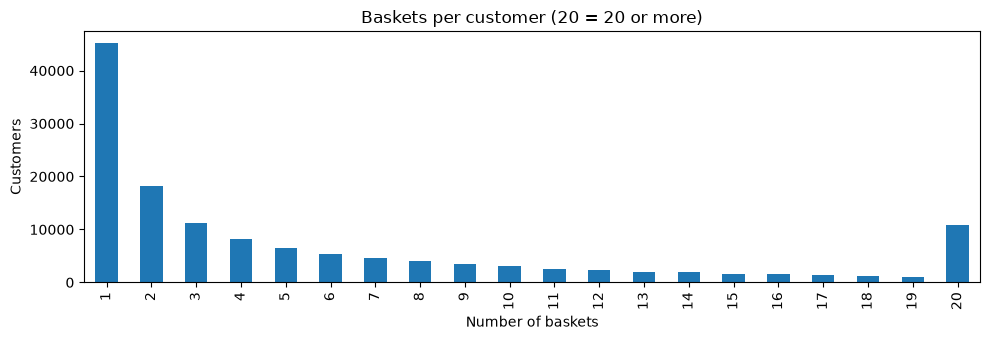

In [17]:
(per_customer["baskets"].clip(upper=20)
    .value_counts().sort_index()
    .plot.bar(figsize=(10, 3.5), title="Baskets per customer (20 = 20 or more)"))
plt.xlabel("Number of baskets")
plt.ylabel("Customers")
plt.tight_layout()
plt.savefig(FIGURES / "01_baskets_per_customer.png", dpi=150)
plt.show()

## 5b. Feasibility check for the discount question

The discount analysis only works if the **same article sells at noticeably different prices**. We compare each purchase with the highest price that article sold for **in the same channel** (online and store prices may differ). A ratio of 1.0 means full price; 0.7 means 30% below.

Prices in this dataset have small rounding noise, so tiny gaps (e.g. 0.99) are not real discounts. We test several thresholds instead of trusting one.

In [18]:
ref = tx.groupby(["article_id", "sales_channel_id"])["price"].transform("max")
tx_price_ratio = tx["price"] / ref

print("Price relative to that article's max price in the same channel:")
print(tx_price_ratio.describe(percentiles=[.05, .1, .25, .5]))
print()
for t in (0.90, 0.85, 0.80, 0.70):
    print(f"Purchases at <= {t:.0%} of max price: {(tx_price_ratio <= t).mean():.1%}")

# How many articles ever show a real price drop?
art_min_ratio = tx_price_ratio.groupby([tx["article_id"], tx["sales_channel_id"]]).min()
print()
print(f"Article-channel pairs with a drop of 15%+: {(art_min_ratio <= 0.85).mean():.1%}")

Price relative to that article's max price in the same channel:


count   3,162,621.0000
mean            0.8604
std             0.2066
min             0.0110
5%              0.3998
10%             0.4997
25%             0.7998
50%             1.0000
max             1.0000
Name: price, dtype: float64

Purchases at <= 90% of max price: 39.2%
Purchases at <= 85% of max price: 32.7%
Purchases at <= 80% of max price: 29.6%
Purchases at <= 70% of max price: 21.2%



Article-channel pairs with a drop of 15%+: 65.0%


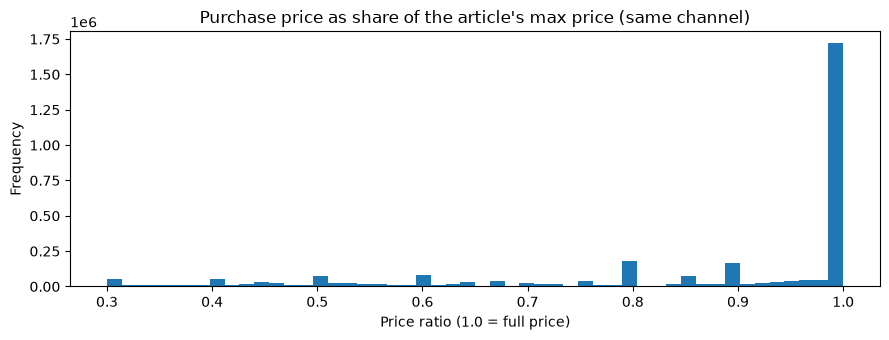

In [19]:
tx_price_ratio.clip(lower=0.3).plot.hist(bins=50, figsize=(9, 3.5),
    title="Purchase price as share of the article's max price (same channel)")
plt.xlabel("Price ratio (1.0 = full price)")
plt.tight_layout()
plt.savefig(FIGURES / "01_price_ratio_distribution.png", dpi=150)
plt.show()

**How to read this:** if a meaningful share of purchases sits at 0.85 or below, the discount question is feasible. If almost everything is at ~1.0, tell me and we'll adjust the definition.

Note that this sample is only 10% of customers, so per-article max prices are based on fewer sales. Notebook 02 rebuilds reference prices from the **full** data.

## 6. Save compact files for the rest of the project

Customer IDs are 64-character hashes, which waste memory and are slow to join in MySQL. We map them to short integers and keep the mapping table.

In [20]:
id_map = pd.DataFrame({"customer_id": customers["customer_id"]})
id_map["cust_key"] = range(1, len(id_map) + 1)
id_map["cust_key"] = id_map["cust_key"].astype("int32")

customers_out = customers.merge(id_map, on="customer_id").drop(columns="customer_id")
customers_out = customers_out[["cust_key"] + [c for c in customers_out.columns if c != "cust_key"]]

tx_out = tx.merge(id_map, on="customer_id").drop(columns="customer_id")
tx_out = tx_out[["t_dat", "cust_key", "article_id", "price", "sales_channel_id"]]

assert len(tx_out) == len(tx), "Row count changed during ID mapping"

id_map.to_parquet(PROCESSED / "customer_id_map.parquet", index=False)
customers_out.to_parquet(PROCESSED / "customers_sample.parquet", index=False)
tx_out.to_parquet(PROCESSED / "transactions_sample_keyed.parquet", index=False)
articles.to_parquet(PROCESSED / "articles.parquet", index=False)

for f in sorted(PROCESSED.glob("*.parquet")):
    print(f"{f.name:40s} {f.stat().st_size/1e6:8.1f} MB")

articles.parquet                              6.4 MB
customer_id_map.parquet                       9.9 MB
customers_sample.parquet                      9.2 MB
transactions_sample.parquet                  77.1 MB
transactions_sample_keyed.parquet            17.1 MB


## 7. What to write down before Week 2

Fill these in from the outputs above (they go into your scope doc and later the README):

- Rows in the sample, date range, and whether the first/last months are partial
- Null rates for `age`, `club_member_status`, `fashion_news_frequency`, `FN`, `Active`, and how you will handle each
- The odd category values you saw (e.g. different spellings of "no newsletter")
- Results of every data-quality check in section 4
- Repeat-customer rate and top-10% revenue share: your first two headline numbers
- Anything surprising in the monthly chart
- From 5b: the share of purchases at <= 85% of max price, and whether discounts look common enough to study

**Next:** run `02_full_weekly_aggregates.ipynb`, which builds the product-level tables for the lifecycle and trend questions.